# Recherche directe de politique


### **Binôme :** Ahdi BEN MAAOUIA & Abderrahim BEN MOHA


Dans ce TP, l'objectif est d'implémenter un algorithme de recherche directe de politique pour trouver une politique optimale pour différents environnements.

> Répondre aux questions (dans les cellules <span style="color:blue">Votre réponse: </span> )


> Le code doit être fonctionnel avec l'environnement virtuel du TP. Si d'autres packages que ceux présents dans l'environnement virtuel créé au départ sont nécessaires, vous devez ajouter à votre dépôt un fichier `environnement.yaml` qui est un export de votre environnement virtuel. Ce fichier est obtenu avec la commande suivante:  ```conda env export > environnement.yaml```

In [1]:
import gymnasium as gym
import random
import numpy as np
from collections import deque
import matplotlib.pyplot as plt
import torch
from torch.distributions import Categorical
%matplotlib inline
%load_ext autoreload

def init_seed(seedval):
    torch.manual_seed(seedval)
    np.random.seed(seedval)
    random.seed(seedval)

# 1 Environnement CartPole

## 1.1 Découverte de l'environnement

Lire la documentation de l'environnement [CartPole-v1](https://gymnasium.farama.org/environments/classic_control/cart_pole/).

Bien comprendre les caractéristiques de cet environnement et compléter ci-dessous:

- états/actions discrets ou continus ? 
- dimensions des espaces d'états et d'actions ?
- signification de *terminated* et *truncated* ?
- durée max d'un épisode ?
- somme des récompenses max par épisode ?

<span style="color:blue">Votre réponse: </span>

<span style="color: white"> Les états sont continus car c'est la position du centre du chariot entre -4.8 et 4.8 ainsi que d'autres caractéristiques physiques comme la vitesse du chariot, l'angle du bâton et sa vitesse angulaire. Les actions sont discrètes et sont au nombres de deux, "aller à droite ou à gauche". Donc la dimension des espaces d'états est 4 et celui des actions est 2.

<span style="color: white">**Termination** c'est quand le chariot dépasse les bords des rails ([-2.4;2.4]) ou quand l'angle du pendule dépasse les ±12°. Tandis que **Truncated** c'est quand l'épisode se termine par limite de temps ce qui est considéré comme un succès dans notre cas. La durée maximale d'un épisode est de 500 pas dans la version 1.
Comme l'environnement donne une récompense de +1 à chaque pas où le pendule reste debout, le score maximal parfait est de 500 points. 


## 1.2 Définition de la Politique


<span style="color:green">- Quelle est la différence entre une politique stochastique et déterministe ?  </span>


<span style="color:blue">Votre réponse: </span>

<span style="color: white">Une politique déterministe associe directement un état donné à une seule action précise. Pour un état s, la politique renvoie toujours la même action a. Tandis qu'une politique stochastique renvoie pour un état s une distribution de probabilité sur l'ensemble des actions possibles. Pour un même état $s$, l'action finale est échantillonnée selon ces probabilités, ce qui introduit de l'aléa.

<span style="color:green">- Dans le cas d'une politique déterministe dans le CartPole, qu'est-ce qui sera en entrée de la politique ? En sortie ?  </span>

<span style="color:blue">Votre réponse: </span>

<span style="color: white">En entrée on aura le vecteur d'état continu de dimension 4 (position, vitesse, angle, vitesse angulaire). En sortie on aura soit 0 pour "aller à gauche" ou 1 pour "aller à droite".

<span style="color:green">- Dans le cas d'une politique stochastique dans le CartPole, qu'est-ce qui sera en entrée de la politique ? En sortie ?  </span>

<span style="color:blue">Votre réponse: </span>

<span style="color: white">En entrée on aura le même vecteur d'état continu de dimension 4 (position, vitesse, angle, vitesse angulaire). En sortie on aura une action discrète (0 ou 1) obtenue par tirage aléatoire à partir des probabilités calculées pour chaque action.

Compléter la classe *Politique* ci-dessous qui sera utilisée dans le CartPole. Cette politique sera déterministe ou stochastique (choix via l'argument *det*) et sera composée d'une seule couche de poids. 
- Vous devez utiliser *ndarray* de NumPy pour les poids, et pas les couches linéaires de *PyTorch* car vous n'aurez pas besoin ici de calcul de gradient. 
- Pour la politique stochastique, vous utiliserez les [distributions catégorielles](https://docs.pytorch.org/docs/main/distributions.html#categorical) de *PyTorch* 

In [2]:
class Politique():

    def __init__(self, dim_entree: int, dim_sortie: int, det = True):
        self.det = det
        self.dim_entree = dim_entree
        self.dim_sortie = dim_sortie
        
        # Initialisation aléatoire des poids
        self.poids = np.random.randn(dim_entree, dim_sortie)
        
    def output(self, etat: np.ndarray) -> int:
        logits = np.dot(etat, self.poids)
        
        if self.det:
            # Mode déterministe on prend l'action avec le plus haut score
            return int(np.argmax(logits))
        else:
            # Mode stochastique on utilise Categorical de PyTorch
            logits_tensor = torch.from_numpy(logits).float()
            dist = Categorical(logits=logits_tensor)
            
            action = dist.sample().item()
            return int(action)
 
    def set_poids(self, poids: np.ndarray):
        self.poids = poids
    
    def get_poids(self) -> np.ndarray:
        return self.poids

    def save(self, file):
        np.save(file, self.poids)

    def load(self, file):
        self.poids = np.load(file)

Compléter la méthode *eval_politique* qui évalue une politique sur plusieurs épisodes, et renvoie la **performance de chaque épisode**, qui est la somme des récompenses obtenues sur chaque épisode.

NB: L'attribut 'init_large' permet d'élargir les bornes définies pour le choix de l'état initial.

In [3]:
def eval_politique(politique, env, seed=5, nb_episodes=100, max_t=1000, same_init=False, init_large=False) -> list:
    """

    Args:
        politique: politique à évaluer
        env: environnement sur lequel on évalue la politique
        seed: graine pour initialiser l'environnement (et donc la séquence d'états initiaux); si
        same_init: si True, on prendra toujours le même état initial sur les episodes (celui défini par la seed); 
                   si False on prendra differents etats initiaux pour chaque épisode (la seed fixe ici la séquence)
        nb_episodes: nombre d'épisodes sur lesquels on évalue la politique
        max_t : nombre maximum de pas d'un épisode
        init_large: si True, élargit les bornes définies pour le choix de l'état initial.

    Returns:
        list:  somme des récompenses obtenues sur chaque épisode
    """
    env.reset(seed=seed) #    init la sequence d etats initiaux: les appels a env.reset() ensuite donneront toujours la meme séquence
    somme_rec_per_epi = []
    for epi in range(0, nb_episodes):
        recs = []
        if init_large:
            if same_init:
                state, _ = env.reset(seed=seed,options={'low':-0.2,'high':0.2})#
            else:
                state, _ = env.reset(options={'low':-0.2,'high':0.2})
        else:
            if same_init:
                state, _ = env.reset(seed=seed)
            else:
                state, _ = env.reset()
        
        for t in range(max_t):
            action = politique.output(state)
            
            next_state, reward, terminated, truncated, info = env.step(action)
            
            recs.append(reward)
            
            state = next_state
            
            # Si l'épisode est terminé ou tronqué, on sort de la boucle
            if terminated or truncated:
                break
                
        # Calculer la somme des récompenses de l'épisode et l'ajouter à la liste globale
        somme_rec_per_epi.append(sum(recs))
        
    return somme_rec_per_epi


On évalue ci-dessous une politique déterministe et une politique stochastique (non-optimisées) sur 5 épisodes, **à partir du même état initial** pour chaque épisode.

In [4]:
env = gym.make('CartPole-v1')#render_mode="human"
init_seed(5)

politique = Politique(dim_entree=4, dim_sortie=2,det=True) 
perf = eval_politique(politique,env,seed=5,nb_episodes=5,same_init=True)
print(f"Perf  = {perf}")

politique = Politique(dim_entree=4, dim_sortie=2,det=False) 
perf = eval_politique(politique,env,seed=5,nb_episodes=5,same_init=True)
print(f"Perf  = {perf}")

Perf  = [48.0, 48.0, 48.0, 48.0, 48.0]
Perf  = [64.0, 22.0, 42.0, 31.0, 13.0]


<span style="color:green">- Analyser les résultats obtenus sur les 2 évaluations: quelle est la différence ? pourquoi ? que peut-on en déduire sur la stochasticité de l'environnement Cart-Pole ? Expliquer/justifier.  </span>

<span style="color:blue">Votre réponse: </span>

<span style="color: white">Pour la politique déterministe l'agent choisit toujours la même action pour un état donné. Il reproduit donc exactement la même séquence de mouvements  ce qui donne le même score pour chaque épisode. Là où l'agent de la politique stochastique tire l'action au sort à partir d'une distribution de probabilités créant des scores totalement différents.

<span style="color: white">Cela nous montre donc que l'environnement CartPole-v1 est strictement déterministe. Le fait d'obtenir un score constant prouve que la transition d'un état s à un état s' via une action a est entièrement régie par des équations mathématiques déterministes et qu'il n'y a donc pas de stochasticité dans cet environnement.

## 1.3 Algorithme de recherche directe de politique

L'objectif est d'implément un algorithme de type *Adaptive Noise Scaling*, qui va à chaque itération, générer une nouvelle politique candidate en perturbant les paramètres de la meilleure politique trouvée. 

La perturbation des paramètres sera réalisée en ajoutant un *bruit* sur chaque paramètre, et en faisant **varier la variance** de ce bruit: variance réduite si la politique candidate trouvée est meilleure que l'ancienne, augmentée sinon.

L'algorithme est le suivant:
- Choix d'une politique initiale arbitraire Pi et évaluation de cette politique
- Tant que l'environnement n'est pas résolu (critere d'arret à définir !)
    - Génération d'une nouvelle politique candidate à partir de Pi
    - Evaluation de la candidate
    - Si la candidate a une meilleure perf que Pi: réduction de la variance du bruit et Pi = Candidate
    - Si la candidate a une moins bonne perf que Pi: augmentation de la variance du bruit 

Pour perturber un poids: `w = w + bruit_std * np.random.randn(1)` avec la variance du bruit augmenté ou réduite tout en restant dans des bornes.

<span style="color:green">Vous devez  </span>
- compléter la méthode *recherche_directe* pour faire une recherche dans l'espace des paramètres de la politique. Cette méthode renverra les performances obtenues à chaque itération et les poids de la meilleure politique trouvée



In [11]:
def recherche_directe(politique, env, nb_iterations=1000, max_t=1000, target_perf=500.0, nb_eval_episodes=5) -> tuple[list, np.ndarray]:
    """
    Optimise les poids de la politique par recherche directe (Adaptive Noise Scaling).

    Args:
        politique: politique à optimiser
        env: environnement sur lequel on évalue la politique
        nb_episodes : nb d'itérations max pour la recherche 
        max_t : nb max de pas par épisode 

    Returns:
        tuple[list,np.ndarray]: liste des performances à chaque épisode de la recherche, et meilleur_poids trouvé
    """
    bruit_std = 1e-1 if target_perf == 200.0 else 1e-2
    historique_perf = []
    
    meilleur_poids = politique.get_poids().copy()
    meilleur_perf = np.mean(eval_politique(politique, env, nb_episodes=nb_eval_episodes, max_t=max_t, same_init=False))
    
    for i_it in range(1, nb_iterations + 1):
        # Perturbation
        bruit = bruit_std * np.random.randn(*meilleur_poids.shape)
        poids_candidat = meilleur_poids + bruit
        politique.set_poids(poids_candidat)
        
        # Évaluation
        perf = np.mean(eval_politique(politique, env, nb_episodes=nb_eval_episodes, max_t=max_t, same_init=False))
        
        # Adaptation du bruit
        if perf >= meilleur_perf:
            bruit_std = max(1e-3, bruit_std / 2)
            meilleur_perf = perf
            meilleur_poids = poids_candidat.copy()
        else:
            bruit_std = min(2.0, bruit_std * 2)
            politique.set_poids(meilleur_poids)
            
        historique_perf.append(meilleur_perf)
        
        # Suivi console optionnel pour le Lander plus tard
        if target_perf == 200.0 and i_it % 50 == 0:
            print(f"Itération {i_it}/{nb_iterations} | Meilleure Perf : {meilleur_perf:.2f}")
            
        # Critère d'arrêt
        if meilleur_perf >= target_perf:
            print(f"Environnement résolu à l'itération {i_it} ! Perf : {meilleur_perf:.2f} >= {target_perf}")
            break
            
    politique.set_poids(meilleur_poids)
    return historique_perf, meilleur_poids

<span style="color:green">- Préciser et justifier le critère d'arrêt que vous avez choisi.  </span>

<span style="color:blue">Votre réponse: </span>

<span style="color: white">L'algorithme s'arrête préocement dès que la performance moyenne de la politique atteint ou dépasse **500.0** sur l'ensemble des épisodes d'évaluation aléatoires. Comme on a vu précédemment le score maximale qu'on peut espérer atteindre est 500. Obtenir ce score signifie que la politique est mathématiquement parfaite et ne peut plus progresser.
De plus, comme l'évaluation est réalisée sur plusieurs épisodes avec des états de départ distincts, valider ce score maximal atteste que la politique trouvée est extrêmement robuste et contrôle parfaitement le système, peu importe sa situation initiale. 

Compléter le code ci-dessous pour:
- rechercher une politique déterministe et une politique stochastique dans l'environnement CartPole
- tracer les performances pendant la recherche
- sauvegarder votre meilleure politique déterministe dans un fichier "best_pi_cartpole_det.npy" et votre meilleure politique stochastique dans un fichier "best_pi_cartpole_stoc.npy".
<span style="color:red"> Vous ajouterez ces 2 fichiers dans votre dépôt github ! </span> 

Recherche pour la politique déterministe...
Environnement résolu à l'itération 66 ! Perf : 500.00 >= 500.0
Fichier 'best_pi_cartpole_det.npy' a bien été sauvegardé.

Recherche pour la politique stochastique...
Environnement résolu à l'itération 40 ! Perf : 500.00 >= 500.0
Fichier 'best_pi_cartpole_stoc.npy' a bien été sauvegardé.



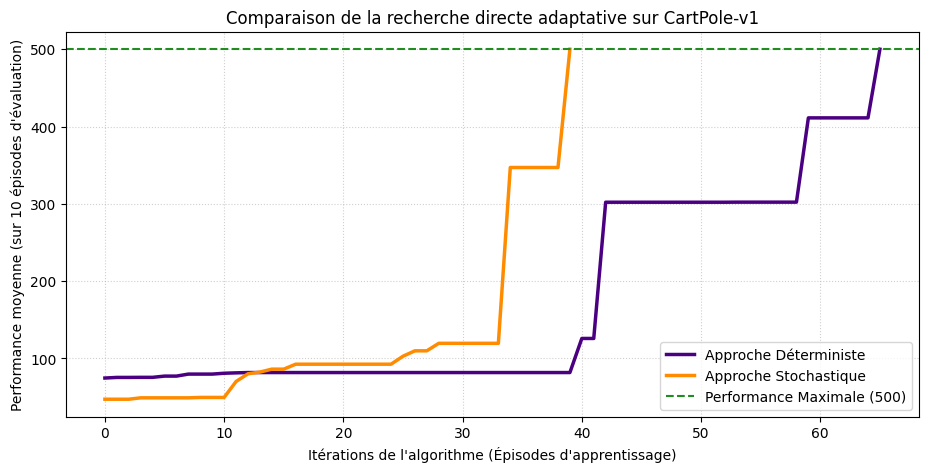

In [12]:
env = gym.make('CartPole-v1')

# Dimensions spécifiques à l'environnement CartPole-v1
dim_entree = env.observation_space.shape[0]
dim_sortie = env.action_space.n

print("Recherche pour la politique déterministe...")
init_seed(5)

politique_det = Politique(dim_entree, dim_sortie, det=True)
hist_perf_det, meilleur_poids_det = recherche_directe(politique_det, env, target_perf=500.0, nb_eval_episodes=10)

# Sauvegarde des poids
politique_det.save("best_pi_cartpole_det.npy")
print("Fichier 'best_pi_cartpole_det.npy' a bien été sauvegardé.\n")


print("Recherche pour la politique stochastique...")
init_seed(5)

politique_stoc = Politique(dim_entree, dim_sortie, det=False)
hist_perf_stoc, meilleur_poids_stoc = recherche_directe(politique_stoc, env, target_perf=500.0, nb_eval_episodes=10)

# Sauvegarde des poids
politique_stoc.save("best_pi_cartpole_stoc.npy")
print("Fichier 'best_pi_cartpole_stoc.npy' a bien été sauvegardé.\n")


plt.figure(figsize=(11, 5))

# Affichage des deux historiques de recherche
plt.plot(hist_perf_det, label="Approche Déterministe", color="indigo", linewidth=2.5)
plt.plot(hist_perf_stoc, label="Approche Stochastique", color="darkorange", linewidth=2.5)

plt.axhline(y=500, color="forestgreen", linestyle="--", label="Performance Maximale (500)")

plt.title("Comparaison de la recherche directe adaptative sur CartPole-v1")
plt.xlabel("Itérations de l'algorithme (Épisodes d'apprentissage)")
plt.ylabel("Performance moyenne (sur 10 épisodes d'évaluation)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)

plt.show()

## 1.4 Evaluation des politiques trouvées

Compléter la cellule ci-dessous pour évaluer les meilleures politiques déterministes et stochastiques que vous avez trouvées, et afficher leurs performances lors de l'évaluation (à partir d'état initiaux différents).


In [13]:
env = gym.make('CartPole-v1')
init_seed(5)

meilleur_poids_det = np.load("best_pi_cartpole_det.npy")  # Charger les poids de la meilleure politique déterministe trouvée
meilleur_poids_stoc = np.load("best_pi_cartpole_stoc.npy")


# On recrée l'objet Politique et on lui injecte les poids optimisés chargés
pi_eval_det = Politique(dim_entree=4, dim_sortie=2, det=True)
pi_eval_det.set_poids(meilleur_poids_det)

perf_100_det = eval_politique(pi_eval_det, env, seed=10, nb_episodes=100, same_init=False)



pi_eval_stoc = Politique(dim_entree=4, dim_sortie=2, det=False)
pi_eval_stoc.set_poids(meilleur_poids_stoc)

perf_100_stoc = eval_politique(pi_eval_stoc, env, seed=10, nb_episodes=100, same_init=False)


print("Bilan de l'évaluation finale sur 100 épisodes :")
print(f"Politique Déterministe | Moyenne : {np.mean(perf_100_det):.2f} | Score Min : {np.min(perf_100_det)} | Score Max : {np.max(perf_100_det)}")
print(f"Politique Stochastique | Moyenne : {np.mean(perf_100_stoc):.2f} | Score Min : {np.min(perf_100_stoc)} | Score Max : {np.max(perf_100_stoc)}")

Bilan de l'évaluation finale sur 100 épisodes :
Politique Déterministe | Moyenne : 500.00 | Score Min : 500.0 | Score Max : 500.0
Politique Stochastique | Moyenne : 500.00 | Score Min : 500.0 | Score Max : 500.0


Afficher quelques épisodes avec vos meilleures politiques stochastiques et déterministes.

In [14]:
import time
import gymnasium as gym

# Création de l'environnement avec rendu pour la visualisation
env_render = gym.make('CartPole-v1', render_mode="human")


print("Test de la politique déterministe...")
for epi in range(2):
    state, _ = env_render.reset()
    terminated = False
    truncated = False
    score = 0
    
    while not (terminated or truncated):
        # Utilisation de la politique déterministe optimisée
        action = pi_eval_det.output(state)
        state, reward, terminated, truncated, _ = env_render.step(action)
        score += reward
        
        time.sleep(0.01)
        
    print(f"↳ Épisode Déterministe {epi+1} fini | Score : {score}")

print("-" * 50)


print("Test de la politique stochastique...")
for epi in range(2):
    state, _ = env_render.reset()
    terminated = False
    truncated = False
    score = 0
    
    while not (terminated or truncated):
        # Utilisation de la politique stochastique optimisée
        action = pi_eval_stoc.output(state)
        state, reward, terminated, truncated, _ = env_render.step(action)
        score += reward
        
        time.sleep(0.01)
        
    print(f"Épisode Stochastique {epi+1} fini | Score : {score}")

env_render.close()
print("\nDémonstration terminée.")

Test de la politique déterministe...
↳ Épisode Déterministe 1 fini | Score : 500.0
↳ Épisode Déterministe 2 fini | Score : 500.0
--------------------------------------------------
Test de la politique stochastique...
Épisode Stochastique 1 fini | Score : 500.0
Épisode Stochastique 2 fini | Score : 500.0

Démonstration terminée.


<span style="color:green"> Analysez vos résultats.  </span>

<span style="color:blue">Votre réponse: </span>

<span style="color: white">L'algorithme de recherche directe (Adaptive Noise Scaling) a réussi à converger vers une matrice de poids optimale capable de généraliser parfaitement. Obtenir un score moyen de 500 sur des épisodes d'évaluation aux états initiaux variés prouve que la politique a véritablement appris à corriger la dynamique du système.

<span style="color: white">En mode déterministe, l'agent sélectionne de manière stricte l'action maximisant le score linéaire et avec très peu de varitaions/perturbations. En mode stochastique, on peut voir quelques vibrations liées aux choix hasardeux que peut faire l'agent, mais les poids sont suffisamment robustes pour rattraper immédiatement l'équilibre au pas suivant.

# 2 Environnement LunarLander avec actions continues

Vous devez maintenant appliquer la méthode par recherche directe de politique à l'environnement [LunarLander](https://gymnasium.farama.org/environments/box2d/lunar_lander/) **avec actions continues**.

<span style="color:green"> Vous devez:  </span>
### 2.1 redéfinir une politique adaptée à un environnement avec actions continues   

<span style="color:green">- Dans le cas d'une politique déterministe dans le LunarLander continu, qu'est-ce qui sera en sortie de la politique ?  </span>

<span style="color:blue">Votre réponse: </span>

<span style="color: white">En sortie de la politique déterministe, on obtiendra directement un vecteur de valeurs réelles continues de dimension 2. Chaque composante de ce vecteur est bornée dans l'intervalle [-1, 1] avec la première composante qui  représente la poussée du moteur principal et la deuxième la poussée des moteurs latéraux.

<span style="color:green">- Dans le cas d'une politique stochastique dans le LunarLander continu, qu'est-ce qui sera en sortie de la politique ?  </span>

<span style="color:blue">Votre réponse: </span>

<span style="color: white">Dans le cas d'une politique stochastique continue, la sortie brute de la couche linéaire ne donne pas directement l'action, mais les paramètres d'une distribution de probabilité continue pour chaque dimension d'action. L'action finale envoyée à l'environnement est ensuite obtenue par échantillonnage dans cette distribution.

Compléter la classe *PolitiqueAContinu* ci-dessous qui sera utilisée dans le LunarLander. Cette politique sera déterministe ou stochastique (choix via l'argument *det*) et sera composée d'une seule couche de poids. 
- Vous pouvez utiliser un écart-type constant à 0.2 et  NumPy . 

In [15]:
class PolitiqueAContinu():

    def __init__(self, dim_entree: int, dim_sortie: int, det = True):
        self.det = det
        self.dim_entree = dim_entree
        self.dim_sortie = dim_sortie
        self.sigma = 0.2
        
        # Initialisation des poids
        self.poids = np.random.randn(dim_entree, dim_sortie) * 0.1
        
    def output(self, etat: np.ndarray) -> np.ndarray:
        # Calcul de la combinaison linéaire
        out_brute = np.dot(etat, self.poids)
        
        if self.det:
            # Mode déterministe
            action = out_brute
        else:
            # Mode stochastique
            bruit_gaussien = np.random.normal(loc=0.0, scale=self.sigma, size=self.dim_sortie)
            action = out_brute + bruit_gaussien
            
        # On sature les actions dans [-1, 1] pour respecter les bornes du LunarLander continu
        return np.clip(action, -1.0, 1.0)
 
    def set_poids(self, poids: np.ndarray):
        self.poids = poids.copy()
    
    def get_poids(self) -> np.ndarray:
        return self.poids

    def save(self, file):
        np.save(file, self.poids)

    def load(self, file):
        self.poids = np.load(file)

### 2.2 effectuer une recherche dans l'espace des paramètres 
Pour trouver une politique déterministe et une politique stochastique (réutiliser en la modifiant si nécessaire la méthode *recherche_directe* implémentée précédemment ).


Sauvegarder votre meilleure politique déterministe dans un fichier "best_pi_lunar_det.npy" et votre meilleure politique stochastique dans un fichier "best_pi_lunar_stoc.npy".
<span style="color:red"> Vous ajouterez ces 2 fichiers dans votre dépôt github ! </span> 


Recherche : LunarLander continu déterministe...
Itération 50/1000 | Meilleure Perf : 65.23
Itération 100/1000 | Meilleure Perf : 77.78
Itération 150/1000 | Meilleure Perf : 169.05
Environnement résolu à l'itération 169 ! Perf : 224.57 >= 200.0
Fichier 'best_pi_lunar_det.npy' sauvegardé.

Recherche : LunarLander continu stochastique...
Itération 50/1000 | Meilleure Perf : 4.90
Itération 100/1000 | Meilleure Perf : 4.90
Itération 150/1000 | Meilleure Perf : 4.90
Itération 200/1000 | Meilleure Perf : 4.90
Itération 250/1000 | Meilleure Perf : 4.90
Itération 300/1000 | Meilleure Perf : 4.90
Itération 350/1000 | Meilleure Perf : 4.90
Itération 400/1000 | Meilleure Perf : 4.90
Itération 450/1000 | Meilleure Perf : 4.90
Itération 500/1000 | Meilleure Perf : 4.90
Itération 550/1000 | Meilleure Perf : 4.90
Itération 600/1000 | Meilleure Perf : 4.90
Itération 650/1000 | Meilleure Perf : 4.90
Itération 700/1000 | Meilleure Perf : 4.90
Itération 750/1000 | Meilleure Perf : 4.90
Itération 800/1000 

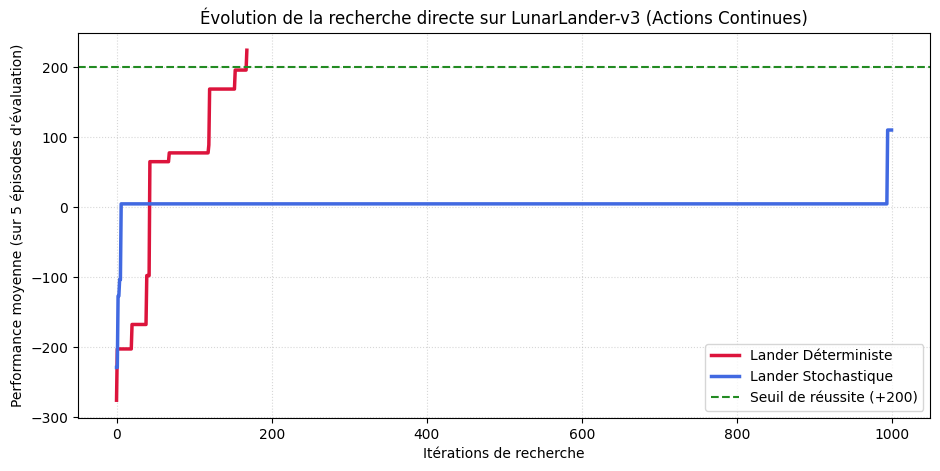

In [17]:
#recherche de politique
env = gym.make("LunarLander-v3",continuous=True)
init_seed(5)

# Configuration des dimensions pour le LunarLander continu
dim_entree = env.observation_space.shape[0]
dim_sortie = env.action_space.shape[0]

# Environnement déterministe
print("Recherche : LunarLander continu déterministe...")
init_seed(5)

pi_lunar_det = PolitiqueAContinu(dim_entree, dim_sortie, det=True)
# On utilise target_perf=200.0 (seuil de réussite officiel du Lander)
hist_lunar_det, meilleur_poids_lunar_det = recherche_directe(
    pi_lunar_det, env, nb_iterations=1000, target_perf=200.0, nb_eval_episodes=5
)

# Sauvegarde du fichier
pi_lunar_det.save("best_pi_lunar_det.npy")
print("Fichier 'best_pi_lunar_det.npy' sauvegardé.\n")


# Environnement stochastique
print("Recherche : LunarLander continu stochastique...")
init_seed(5)

pi_lunar_stoc = PolitiqueAContinu(dim_entree, dim_sortie, det=False)
hist_lunar_stoc, meilleur_poids_lunar_stoc = recherche_directe(
    pi_lunar_stoc, env, nb_iterations=1000, target_perf=200.0, nb_eval_episodes=5
)

# Sauvegarde du fichier
pi_lunar_stoc.save("best_pi_lunar_stoc.npy")
print("Fichier 'best_pi_lunar_stoc.npy' sauvegardé.\n")


# Tracé des courbes de convergence
plt.figure(figsize=(11, 5))
plt.plot(hist_lunar_det, label="Lander Déterministe", color="crimson", linewidth=2.5)
plt.plot(hist_lunar_stoc, label="Lander Stochastique", color="royalblue", linewidth=2.5)
plt.axhline(y=200, color="forestgreen", linestyle="--", label="Seuil de réussite (+200)")

plt.title("Évolution de la recherche directe sur LunarLander-v3 (Actions Continues)")
plt.xlabel("Itérations de recherche")
plt.ylabel("Performance moyenne (sur 5 épisodes d'évaluation)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.5)
plt.show()

### 2.3  évaluer les meilleures politiques stochastique et déterministes trouvées

In [20]:
#evaluation

init_seed(5)

# Environnement déterministe
pi_eval_lunar_det = PolitiqueAContinu(dim_entree, dim_sortie, det=True)
pi_eval_lunar_det.load("best_pi_lunar_det.npy")

perf_100_lunar_det = eval_politique(pi_eval_lunar_det, env, seed=42, nb_episodes=100, same_init=False)

# Environnement stochastique
pi_eval_lunar_stoc = PolitiqueAContinu(dim_entree, dim_sortie, det=False)
pi_eval_lunar_stoc.load("best_pi_lunar_stoc.npy")

perf_100_lunar_stoc = eval_politique(pi_eval_lunar_stoc, env, seed=42, nb_episodes=100, same_init=False)

# Bilan de l'évaluation finale
print("Résultats de l'évaluation finale sur 100 épisodes :")
print(f"Politique Déterministe : Moyenne = {np.mean(perf_100_lunar_det):.2f} | Min = {np.min(perf_100_lunar_det):.2f} | Max = {np.max(perf_100_lunar_det):.2f}")
print(f"Politique Stochastique : Moyenne = {np.mean(perf_100_lunar_stoc):.2f} | Min = {np.min(perf_100_lunar_stoc):.2f} | Max = {np.max(perf_100_lunar_stoc):.2f}")

Résultats de l'évaluation finale sur 100 épisodes :
Politique Déterministe : Moyenne = 132.49 | Min = -513.25 | Max = 294.78
Politique Stochastique : Moyenne = 0.91 | Min = -406.56 | Max = 239.80


<span style="color:green"> Analysez vos résultats.  </span>

<span style="color: white">Dans le cas d'une politique stochastique continue, la sortie brute de la couche linéaire ne donne pas directement l'action, mais les paramètres d'une distribution de probabilité continue pour chaque dimension d'action. L'action finale envoyée à l'environnement est ensuite obtenue par échantillonnage dans cette distribution.